# Lab 4 — ANOVA, correlation and regression

**Lecture sessions 8–9.**

Explain an F ratio, interpret marginal and adjusted associations, distinguish an interval for a mean
from a prediction interval, and evaluate a selected model on observations held aside from development.

**Activities**

1. Define the questions and set aside test observations
2. Compare three branch means with ANOVA
3. Inspect correlation and a scatterplot
4. Interpret a simple regression and prediction intervals
5. Adjust for other variables and inspect residuals
6. Select on development data and evaluate on the test set
7. Write a statistical report

Run the supplied cells in order. Focus on the question, estimates, assumptions and predictions.
The optional sections after the exit task explore variance tests, selection algorithms and diagnostics in more detail.

## 1. Questions and observations

**Lecture sessions 8–9: the response and observational unit determine the analysis.**
The branch example asks whether three branches have equal mean loan interest rates.
Each row is a loan-rate observation, recorded in percent.

The state-poverty dataset contains 51 US state/District of Columbia rows. It asks how
state-level poverty percentages are associated with other state-level percentages. The fields are
metropolitan residence (`metro_res`), white population (`white`), high-school graduates (`hs_grad`)
and female householders with no husband present (`female_house`).

Interpret these observational data at the state level. Assess individual-level or causal questions
using a study designed for those questions. For prediction, set aside 11 rows before exploring
the other 40.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
import statsmodels.api as sm
from statsmodels.formula.api import ols
# Open the notebook from its own folder or from the repository root.
DATA = Path('.') if Path('state-poverty.csv').exists() else Path('Lab4')
if not (DATA / 'state-poverty.csv').exists():
    raise FileNotFoundError('Open this notebook from Lab4 or the repository root.')
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
pd.set_option('display.max_columns', 12)

In [2]:
branches = pd.read_csv(DATA / 'banking-interest-rates.csv')
states = pd.read_csv(DATA / 'state-poverty.csv')
split_rng = np.random.default_rng(409)
order = split_rng.permutation(len(states))
development = states.iloc[order[:40]].copy()
test = states.iloc[order[40:]].copy()
print(f'Development rows: {len(development)}; held-aside test rows: {len(test)}')
# Explore only development data until a model has been selected.
display(development.head())

Development rows: 40; held-aside test rows: 11


,state,metro_res,white,hs_grad,poverty,female_house
33,North Carolina,60.2,74.1,81.4,13.1,12.5
24,Mississippi,48.8,61.2,81.2,17.6,17.3
27,Nebraska,69.8,92.1,90.8,9.5,9.1
10,Georgia,71.6,67.5,85.1,12.1,14.5
12,Idaho,66.4,95.5,88.2,11.8,8.7


## 2. Compare several means with ANOVA

**Lecture session 8: compare between-group variation with within-group noise.**
Test $H_0:\mu_A=\mu_B=\mu_C$ against the alternative that at least one mean differs.
The one-way ANOVA statistic is $F=MS_{between}/MS_{within}$.
The reference F distribution assumes independent observations, normal within-group errors and a common error variance.

**Predict:** Would separating the branch means while retaining each branch's spread increase F?

,count,mean,std
Branch,,,
Branch A,30,5.677,0.440
Branch B,30,5.884,0.366
Branch C,30,5.747,0.386


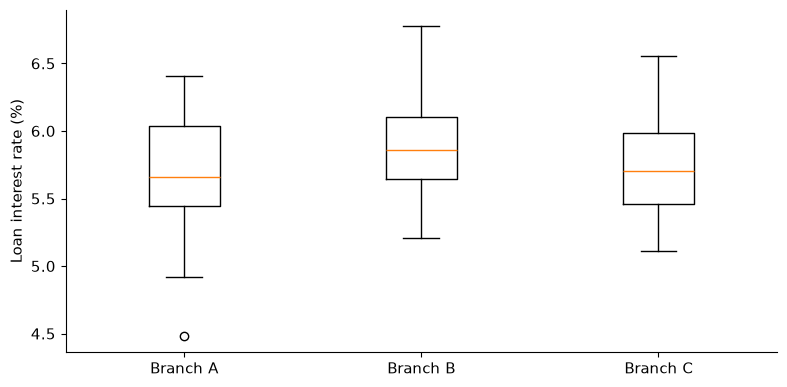

,sum_sq,df,F,PR(>F)
C(Branch),0.666369,2.0,2.097883,0.128881
Residual,13.817291,87.0,NaN,NaN


Between SS=0.6664, within SS=13.8173, F=2.0979, p=0.1289


In [3]:
display(branches.groupby('Branch')['Interest_Rate'].agg(['count', 'mean', 'std']).round(3))
groups = [g['Interest_Rate'].to_numpy() for _, g in branches.groupby('Branch')]
plt.boxplot(groups, tick_labels=sorted(branches['Branch'].unique()))
plt.ylabel('Loan interest rate (%)')
plt.tight_layout()
plt.show()

# C(Branch) treats the branch label as categorical; the model includes an intercept.
anova_model = ols('Interest_Rate ~ C(Branch)', data=branches).fit()
anova_table = sm.stats.anova_lm(anova_model, typ=2)
display(anova_table)
group_sizes = branches.groupby('Branch').size()
group_means = branches.groupby('Branch')['Interest_Rate'].mean()
grand_mean = branches['Interest_Rate'].mean()
ss_between = (group_sizes*(group_means-grand_mean)**2).sum()
ss_within = sum(((values-values.mean())**2).sum() for values in groups)
k, N = len(groups), len(branches)
f_manual = (ss_between/(k-1))/(ss_within/(N-k))
print(f'Between SS={ss_between:.4f}, within SS={ss_within:.4f}, F={f_manual:.4f}, p={stats.f.sf(f_manual, k-1, N-k):.4g}')

**Discuss:** Identify the numerator and denominator degrees of freedom. What conclusion follows
at 5%? If the overall test rejected, would that alone identify which pair differs?

<details>
<summary>Check your reasoning</summary>

Here p is about 0.129, so the 5% test does not reject equal branch means.
The degrees of freedom are 2 and 87. The numerator measures separation of the three means
relative to the overall mean; the denominator measures variation remaining within branches.
An overall rejection supports at least one mean difference. A specific pairwise claim needs its
own planned comparison or an appropriate multiple-comparison procedure.

</details>

## 3. Describe a relationship

**Lecture session 8: correlation measures linear association.** Use the 40 development rows.
Predict the signs of the associations of poverty with graduation and household composition,
then inspect a plot before interpreting Pearson's correlation.

,poverty,metro_res,white,hs_grad,female_house
poverty,1.000,-0.196,-0.350,-0.769,0.524
metro_res,-0.196,1.000,-0.326,0.066,0.301
white,-0.350,-0.326,1.000,0.296,-0.890
hs_grad,-0.769,0.066,0.296,1.000,-0.556
female_house,0.524,0.301,-0.890,-0.556,1.000


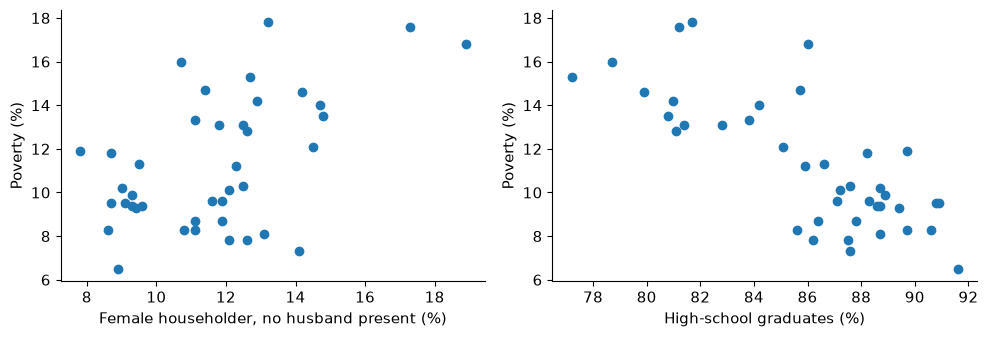

Pearson r=0.524; two-sided p=0.0005194


In [4]:
predictors = ['metro_res', 'white', 'hs_grad', 'female_house']
variables = ['poverty'] + predictors
correlations = development[variables].corr()
display(correlations.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(development['female_house'], development['poverty'])
axes[0].set(xlabel='Female householder, no husband present (%)', ylabel='Poverty (%)')
axes[1].scatter(development['hs_grad'], development['poverty'])
axes[1].set(xlabel='High-school graduates (%)', ylabel='Poverty (%)')
plt.tight_layout()
plt.show()
pearson = stats.pearsonr(development['female_house'], development['poverty'])
print(f'Pearson r={pearson.statistic:.3f}; two-sided p={pearson.pvalue:.4g}')

**Discuss:** Does correlation have units? Would multiplying both percentage columns by 0.01 change r?
Which plot features could make one correlation coefficient a poor summary?

Curvature, clusters and influential observations need inspection. The usual Pearson p-value uses
an independent bivariate-normal sampling model; a collection of neighbouring states does not
automatically satisfy that design. Treat the inference calculations here as conditional on the model.

## 4. Fit a simple regression

**Lecture session 8: an estimated slope has response units per predictor unit.**
Fit $poverty_i=\beta_0+\beta_1 female\_house_i+\varepsilon_i$.
The slope describes a change in predicted poverty **percentage points** for a one-percentage-point
increase in the predictor. It describes a state-level association.

**Predict:** Should a prediction interval for one further state's poverty percentage be wider than
an interval for the mean poverty percentage at the same predictor value?

,estimate,SE,p-value,95% lower,95% upper
Intercept,3.6444,2.0575,0.0845,-0.5208,7.8097
female_house,0.6531,0.1722,0.0005,0.3045,1.0017


R²=0.275; residual SD=2.587 percentage points
Slope t²=14.3857; overall F=14.3857


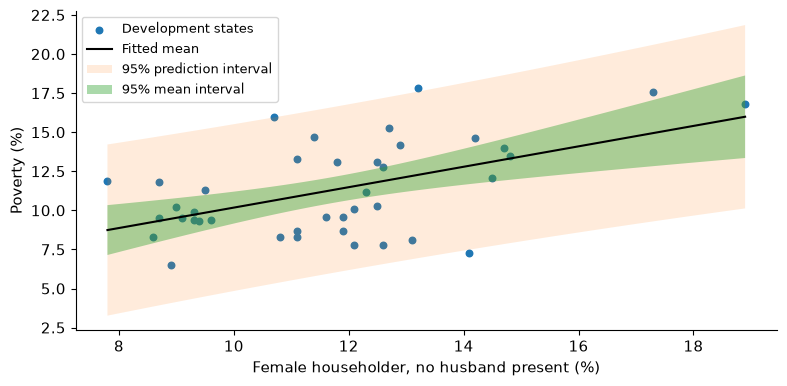

In [5]:
simple = ols('poverty ~ female_house', data=development).fit()
simple_coefficients = pd.DataFrame({'estimate': simple.params, 'SE': simple.bse,
                                    'p-value': simple.pvalues,
                                    '95% lower': simple.conf_int()[0], '95% upper': simple.conf_int()[1]})
display(simple_coefficients.round(4))
print(f'R²={simple.rsquared:.3f}; residual SD={np.sqrt(simple.mse_resid):.3f} percentage points')
print(f'Slope t²={simple.tvalues["female_house"]**2:.4f}; overall F={simple.fvalue:.4f}')

grid = pd.DataFrame({'female_house': np.linspace(development['female_house'].min(),
                                                development['female_house'].max(), 80)})
prediction = simple.get_prediction(grid).summary_frame(alpha=0.05)
x = grid['female_house'].to_numpy()
plt.scatter(development['female_house'], development['poverty'], s=22, label='Development states')
plt.plot(x, prediction['mean'], color='black', label='Fitted mean')
plt.fill_between(x, prediction['obs_ci_lower'], prediction['obs_ci_upper'], alpha=0.15, label='95% prediction interval')
plt.fill_between(x, prediction['mean_ci_lower'], prediction['mean_ci_upper'], alpha=0.4, label='95% mean interval')
plt.xlabel('Female householder, no husband present (%)')
plt.ylabel('Poverty (%)')
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

<details>
<summary>Check your reasoning</summary>

The mean interval quantifies uncertainty in the fitted population mean at a specified predictor value.
A prediction interval additionally includes variation of a new outcome around that mean, so it is wider.
For simple OLS with an intercept, R² equals the squared sample correlation and the slope's t statistic
squared equals the overall F statistic. Classical intervals assume the stated linear model with independent,
constant-variance normal errors. Interpreting the intercept at 0% extrapolates beyond these data.

</details>

**Your response:** Interpret the fitted slope and one interval in words. State the scale of observation.

## 5. Multiple regression and diagnostics

**Lecture session 9: a coefficient is conditional on the other included predictors.**
Fit all four predictors. Compare the `female_house` coefficient with the simple-regression coefficient.
“Holding the other predictors fixed” is a statement about the fitted relationship, not a claim
that those variables were experimentally controlled.

**Predict:** Can adding predictors reduce ordinary training $R^2$? Can it reduce adjusted $R^2$?

,estimate,SE,p-value,95% lower,95% upper
Intercept,60.8937,17.3474,0.0013,25.6767,96.1108
metro_res,-0.0442,0.0209,0.0418,-0.0866,-0.0017
white,-0.0311,0.0637,0.6291,-0.1605,0.0984
hs_grad,-0.5309,0.1192,0.0001,-0.7729,-0.2890
female_house,0.1508,0.3749,0.6900,-0.6103,0.9118


,R²,adjusted R²,AIC,BIC
simple,0.275,0.256,191.509,194.887
multiple,0.653,0.613,168.054,176.499


Partial F test: do metro_res, white and hs_grad jointly add information?


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,38.0,254.356111,0.0,NaN,NaN,NaN
1,35.0,121.797855,3.0,132.558256,12.697375,0.000009


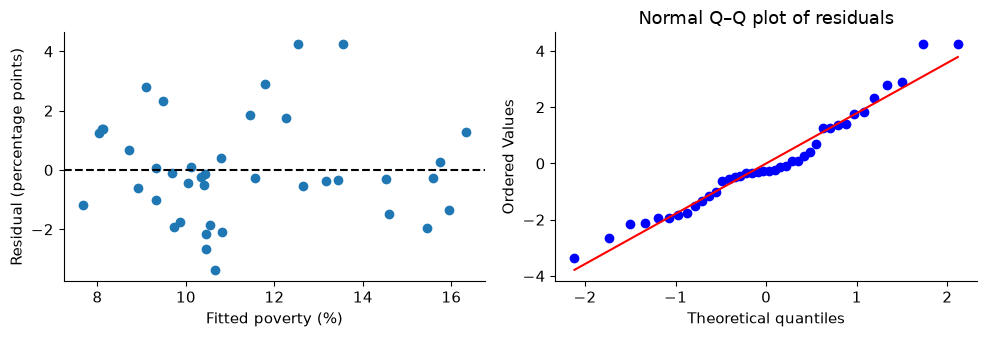

In [6]:
full_formula = 'poverty ~ metro_res + white + hs_grad + female_house'
multiple = ols(full_formula, data=development).fit()
display(pd.DataFrame({'estimate': multiple.params, 'SE': multiple.bse,
                      'p-value': multiple.pvalues, '95% lower': multiple.conf_int()[0],
                      '95% upper': multiple.conf_int()[1]}).round(4))
display(pd.DataFrame({'R²': [simple.rsquared, multiple.rsquared],
                      'adjusted R²': [simple.rsquared_adj, multiple.rsquared_adj],
                      'AIC': [simple.aic, multiple.aic], 'BIC': [simple.bic, multiple.bic]},
                     index=['simple', 'multiple']).round(3))
print('Partial F test: do metro_res, white and hs_grad jointly add information?')
display(sm.stats.anova_lm(simple, multiple))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(multiple.fittedvalues, multiple.resid)
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set(xlabel='Fitted poverty (%)', ylabel='Residual (percentage points)')
stats.probplot(multiple.resid, dist='norm', plot=axes[1])
axes[1].set_title('Normal Q–Q plot of residuals')
plt.tight_layout()
plt.show()

**Discuss:** Look for curvature, changing residual spread and unusual residuals. Which assumption
needs information about how the states are related, rather than a residual plot?
Coefficient tests and the partial F test answer different questions: one adjusted coefficient
versus a set of additional coefficients.

<details>
<summary>Check your reasoning</summary>

Training R² cannot decrease when additional columns are included in a nested OLS model on the same rows.
Adjusted R² can decrease because it accounts for parameter count. AIC and BIC also penalise complexity;
lower values are preferred when comparing models for the same response on the same observations.
Residual patterns guide model checks. Independence needs design or dependence information, such as
shared regional influences. A model with more predictors can still predict less accurately.

</details>

## 6. Select, then evaluate

**Lecture session 9: validation must include the selection step.** Three candidate models are specified below.
Use five-fold cross-validation within the 40 development rows to choose a model by RMSE.
Each prediction is made for a row excluded from that fold's fit. Then refit the chosen model on all
40 development rows and evaluate it once on the 11 held-aside test rows.

**Predict:** Will the largest training $R^2$ necessarily give the smallest cross-validation error?

In [7]:
candidate_formulas = {
    'simple': 'poverty ~ female_house',
    'two predictors': 'poverty ~ female_house + hs_grad',
    'four predictors': full_formula
}
cv_rng = np.random.default_rng(410)
folds = np.array_split(cv_rng.permutation(len(development)), 5)
cv_rows = []
for name, formula in candidate_formulas.items():
    heldout_predictions = np.empty(len(development))
    for validation_positions in folds:
        train_positions = np.setdiff1d(np.arange(len(development)), validation_positions)
        fit = ols(formula, data=development.iloc[train_positions]).fit()
        heldout_predictions[validation_positions] = fit.predict(development.iloc[validation_positions])
    errors = development['poverty'].to_numpy() - heldout_predictions
    train_fit = ols(formula, data=development).fit()
    cv_rows.append([name, train_fit.rsquared, np.sqrt(np.mean(errors**2)), np.mean(np.abs(errors))])
cv_table = pd.DataFrame(cv_rows, columns=['model', 'training R²', 'CV RMSE', 'CV MAE']).set_index('model')
display(cv_table.round(3))
chosen_name = cv_table['CV RMSE'].idxmin()
chosen = ols(candidate_formulas[chosen_name], data=development).fit()
print('Model selected using development data:', chosen_name)

# This is the first use of test outcomes to assess a model.
test_predictions = chosen.predict(test)
test_errors = test['poverty'] - test_predictions
baseline_errors = test['poverty'] - development['poverty'].mean()
display(pd.DataFrame({
    'test RMSE': [np.sqrt(np.mean(test_errors**2)), np.sqrt(np.mean(baseline_errors**2))],
    'test MAE': [np.mean(np.abs(test_errors)), np.mean(np.abs(baseline_errors))]
}, index=[chosen_name, 'development-mean baseline']).round(3))

,training R²,CV RMSE,CV MAE
model,,,
simple,0.275,2.613,2.131
two predictors,0.605,2.369,1.695
four predictors,0.653,2.349,1.722


Model selected using development data: four predictors


,test RMSE,test MAE
four predictors,2.203,1.877
development-mean baseline,3.435,2.580


**Discuss:** Report prediction error in percentage points and compare it with the mean-only baseline.
Why would choosing another model after inspecting these test errors turn this test set into
development data? With only 11 test states, explain why a single split provides an imprecise assessment.

If the intended target were a future year or a new region, the split should reflect that target.
Any transformations, imputation or variable selection learned from data must also be fitted within
the development/fold-training data. Our three formulas use already recorded numeric columns.

## 7. Exit task

**Your response:** Write a short report containing the ANOVA conclusion, one adjusted regression
coefficient, a residual check, the selected model's test error against the baseline, and the population
or prediction target for which the analysis is relevant. Separate association, inference and prediction.

---

## Optional investigation A — Matrix and formula notation; correlation graphics

**Lecture sessions 8–9.** A formula supplies an intercept automatically. In the matrix interface,
add the intercept column explicitly. Both approaches solve the same least-squares problem.

,formula estimate,matrix estimate
Intercept,60.893730,60.893730
metro_res,-0.044179,-0.044179
white,-0.031067,-0.031067
hs_grad,-0.530935,-0.530935
female_house,0.150761,0.150761


Largest absolute fitted-value difference: 0.0


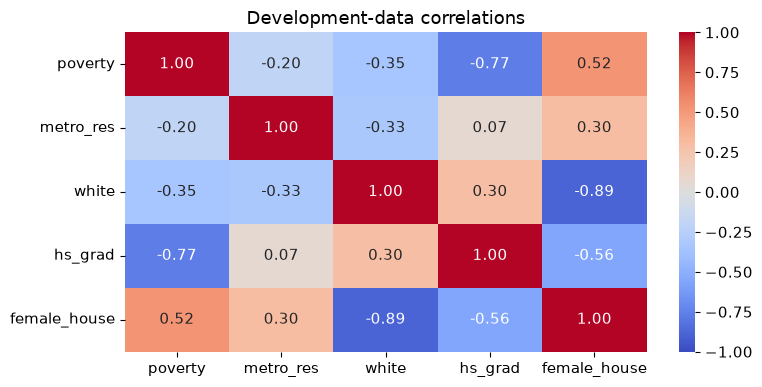

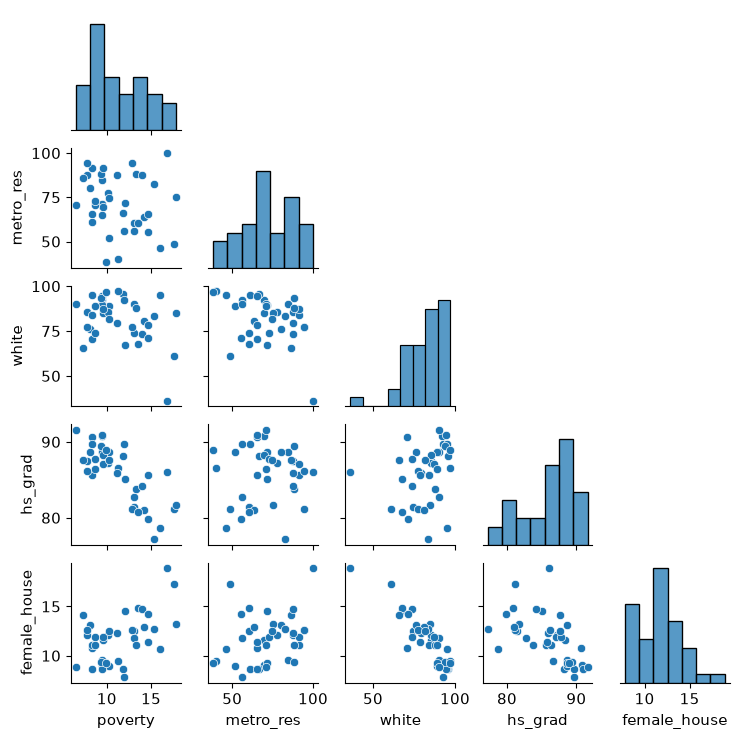

In [8]:
matrix_fit = sm.OLS(development['poverty'], sm.add_constant(development[predictors])).fit()
display(pd.DataFrame({'formula estimate': multiple.params.to_numpy(),
                      'matrix estimate': matrix_fit.params.to_numpy()}, index=multiple.params.index))
print('Largest absolute fitted-value difference:', np.max(np.abs(matrix_fit.fittedvalues-multiple.fittedvalues)))

import seaborn as sns
sns.heatmap(correlations, annot=True, fmt='.2f', vmin=-1, vmax=1, center=0, cmap='coolwarm')
plt.title('Development-data correlations')
plt.tight_layout()
plt.show()
sns.pairplot(development[variables], corner=True, diag_kind='hist', height=1.5)
plt.show()

## Optional investigation B — Model-selection paths

**Lecture session 9.** Forward selection starts with an intercept; backward elimination starts with all predictors.
At each step, try one addition or removal and keep it only if the criterion improves.
Compare adjusted-$R^2$ paths with p-value paths (entry/removal level 0.05).
The code is supplied to inspect the selected variables, not to memorise the loops.

For four predictors there are $2^4=16$ subsets including the intercept-only model.
A greedy path need not reach the best subset. Selection on the same responses changes the
interpretation of subsequent p-values; ordinary output does not account for the search.

In [9]:
from itertools import combinations

def fit_subset(names):
    formula = 'poverty ~ ' + (' + '.join(names) if names else '1')
    return ols(formula, data=development).fit()

subset_rows = []
for size in range(len(predictors)+1):
    for names in combinations(predictors, size):
        fit = fit_subset(list(names))
        subset_rows.append([' + '.join(names) or 'intercept only', fit.rsquared_adj, fit.aic, fit.bic])
subset_table = pd.DataFrame(subset_rows, columns=['predictors', 'adjusted R²', 'AIC', 'BIC'])
display(subset_table.sort_values('adjusted R²', ascending=False).round(3))

def selection_path(direction, criterion, threshold=0.05):
    selected = [] if direction == 'forward' else list(predictors)
    path = []
    while True:
        current = fit_subset(selected)
        path.append([' + '.join(selected) or 'intercept only', current.rsquared_adj])
        candidates = [p for p in predictors if p not in selected] if direction == 'forward' else list(selected)
        if not candidates:
            break
        if criterion == 'adjusted R²':
            trials = []
            for variable in candidates:
                names = selected+[variable] if direction == 'forward' else [p for p in selected if p != variable]
                trials.append((fit_subset(names).rsquared_adj, names))
            score, names = max(trials, key=lambda item: item[0])
            if score <= current.rsquared_adj + 1e-12:
                break
        elif direction == 'forward':
            trials = [(fit_subset(selected+[p]).pvalues[p], p) for p in candidates]
            p_value, variable = min(trials, key=lambda item: item[0])
            if p_value >= threshold:
                break
            names = selected+[variable]
        else:
            variable = current.pvalues[selected].idxmax()
            if current.pvalues[variable] <= threshold:
                break
            names = [p for p in selected if p != variable]
        selected = names
    return pd.DataFrame(path, columns=['predictors', 'adjusted R²'])

for direction in ['forward', 'backward']:
    for criterion in ['adjusted R²', 'p-value']:
        print(direction, criterion)
        display(selection_path(direction, criterion))

,predictors,adjusted R²,AIC,BIC
11,metro_res + white + hs_grad,0.622,166.239,172.994
13,metro_res + hs_grad + female_house,0.621,166.325,173.080
15,metro_res + white + hs_grad + female_house,0.613,168.054,176.499
6,metro_res + hs_grad,0.593,168.334,173.400
8,white + hs_grad,0.587,168.855,173.922
10,hs_grad + female_house,0.584,169.148,174.214
3,hs_grad,0.581,168.486,171.864
14,white + hs_grad + female_house,0.576,170.855,177.610
12,metro_res + white + female_house,0.410,184.024,190.779
7,metro_res + female_house,0.381,185.071,190.137


forward adjusted R²


,predictors,adjusted R²
0,intercept only,-2.220446e-16
1,hs_grad,5.813198e-01
2,hs_grad + metro_res,5.925315e-01
3,hs_grad + metro_res + white,6.219644e-01


forward p-value


,predictors,adjusted R²
0,intercept only,-2.220446e-16
1,hs_grad,5.813198e-01


backward adjusted R²


,predictors,adjusted R²
0,metro_res + white + hs_grad + female_house,0.612952
1,metro_res + white + hs_grad,0.621964


backward p-value


,predictors,adjusted R²
0,metro_res + white + hs_grad + female_house,0.612952
1,metro_res + white + hs_grad,0.621964
2,metro_res + hs_grad,0.592532
3,hs_grad,0.581320


If one of these search algorithms is the proposed prediction procedure, run the entire search
within each cross-validation training fold. Searching on all development rows before cross-validation
would let validation outcomes influence predictor selection. The core exercise instead compares
three specified formulas without using the test set to choose them.

## Optional investigation C — Collinearity, influence and robust standard errors

**Lecture session 9.** VIF measures how well the other predictors explain a predictor. Leverage describes
unusual predictor combinations; a residual describes an unusual response given the fitted model.
Cook's distance combines these ingredients to assess influence. Investigate flagged observations
in context before changing the dataset.

In [10]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
design = sm.add_constant(development[predictors])
display(pd.Series({column: variance_inflation_factor(design.to_numpy(), j)
                   for j, column in enumerate(design.columns) if column != 'const'}, name='VIF').round(3))
influence = multiple.get_influence().summary_frame()
influence['state'] = development['state']
display(influence[['state', 'hat_diag', 'student_resid', 'cooks_d']].sort_values('cooks_d', ascending=False).head())
robust = multiple.get_robustcov_results(cov_type='HC3')
display(pd.DataFrame({'coefficient': multiple.params, 'classical SE': multiple.bse,
                      'HC3 SE': robust.bse}).round(4))

metro_res       1.204
white           6.636
hs_grad         2.145
female_house    9.117
Name: VIF, dtype: float64

,state,hat_diag,student_resid,cooks_d
8,District of Columbia,0.437942,3.501850,1.445759
31,New Mexico,0.111956,2.606788,0.146999
34,North Dakota,0.154768,1.673154,0.097507
20,Maryland,0.096744,-1.976887,0.077293
24,Mississippi,0.328127,0.824979,0.067089


,coefficient,classical SE,HC3 SE
Intercept,60.8937,17.3474,14.9253
metro_res,-0.0442,0.0209,0.0178
white,-0.0311,0.0637,0.0968
hs_grad,-0.5309,0.1192,0.0980
female_house,0.1508,0.3749,0.3837


HC3 changes the estimated coefficient uncertainty, leaving OLS point estimates unchanged.
It addresses heteroskedasticity under independent errors; dependence between states requires a
dependence-aware design or method. Collinearity can inflate coefficient uncertainty even when prediction remains useful.

## Optional investigation D — Inference for variances

**Lecture session 7 reference and lecture session 8.** Under independent normal sampling, a single variance uses a
chi-square reference distribution and a ratio of independent sample variances uses F.
These variance procedures are sensitive to departures from normality.

In [11]:
# Stipulated normal approval-time populations; units are days.
rng = np.random.default_rng(411)
a = rng.normal(5, 2, 30)
b = rng.normal(5, 2.5, 25)
variance0 = 4.0
df = len(a)-1
variance_stat = df*a.var(ddof=1)/variance0
variance_p = min(1.0, 2*min(stats.chi2.cdf(variance_stat, df), stats.chi2.sf(variance_stat, df)))
variance_ci = df*a.var(ddof=1)/stats.chi2.ppf([0.975, 0.025], df)
print(f'One variance: statistic={variance_stat:.3f}, p={variance_p:.4g}, 95% CI={variance_ci} days²')
ratio = a.var(ddof=1)/b.var(ddof=1)
df1, df2 = len(a)-1, len(b)-1
ratio_p = min(1.0, 2*min(stats.f.cdf(ratio, df1, df2), stats.f.sf(ratio, df1, df2)))
print(f'Two variances: F={ratio:.3f}, df=({df1}, {df2}), p={ratio_p:.4g}')
print('Branch variances, Bartlett:', stats.bartlett(*groups))
print('Branch variances, median-centred Levene:', stats.levene(*groups, center='median'))

One variance: statistic=24.256, p=0.5675, 95% CI=[2.12198534 6.04608878] days²
Two variances: F=0.386, df=(29, 24), p=0.01547
Branch variances, Bartlett: BartlettResult(statistic=np.float64(1.0584004965392921), pvalue=np.float64(0.5890758958082437))
Branch variances, median-centred Levene: LeveneResult(statistic=np.float64(0.3936354813691462), pvalue=np.float64(0.6757952512102368))


Bartlett tests equal variances under normal sampling; median-centred Levene is less sensitive to
non-normality. These tests concern variability, whereas ANOVA concerns means. A non-significant
variance test does not prove equal variances, and it is not a compulsory gate before using Welch's two-sample test.

## Data guide

`banking-interest-rates.csv`: 90 illustrative loan interest rates, 30 per labelled branch. `Interest_Rate`
is in percent. Use the stated independent, normal, equal-variance model for this illustrative
branch comparison.

`state-poverty.csv`: 51 state/District of Columbia records. `state` is the location label; the five
numeric fields are percentages. Use these records to examine state-level associations. The
reference year and primary source are unspecified, so interpret the results within this dataset.
Column names describe the recorded quantities.